CWD: C:\Users\hp\sdg_project
STEP 1 DONE - SHA-256: d45ef865f10dc8f3101c258685585ad3bdbb4f9ca5d44ef00de0b67de6d85f9c
STEP 2 DONE
STEP 3 DONE
STEP 4 DONE
{
  "schema_ok": true,
  "range_violations": 0,
  "nan_cells": 0,
  "duplicates": 0,
  "zero_rows": 446,
  "leakage_corr_max": 0.9121424504118676
}
STEP 5 DONE - counterexample: Syrian Arab Republic (SYR)
ANALYSIS DONE
{
  "n_countries": 40,
  "mean_cagr_g3": 0.025983512799700424,
  "mean_cagr_g4": 0.033273806387091175,
  "mean_diff": -0.007290293587390748,
  "median_diff": 0.005715941394872193,
  "paired_t": -1.0588247260079153,
  "p_value": 0.2961937262186126,
  "ci95_lo": -0.022008667098634742,
  "ci95_hi": 0.00447385285231596,
  "ci_contains_zero": true,
  "loo_mean_range": [
    -0.008713122140894215,
    -0.0028974778312020233
  ],
  "sign_test_p": 0.6358280026288412,
  "n_positive": 22
}


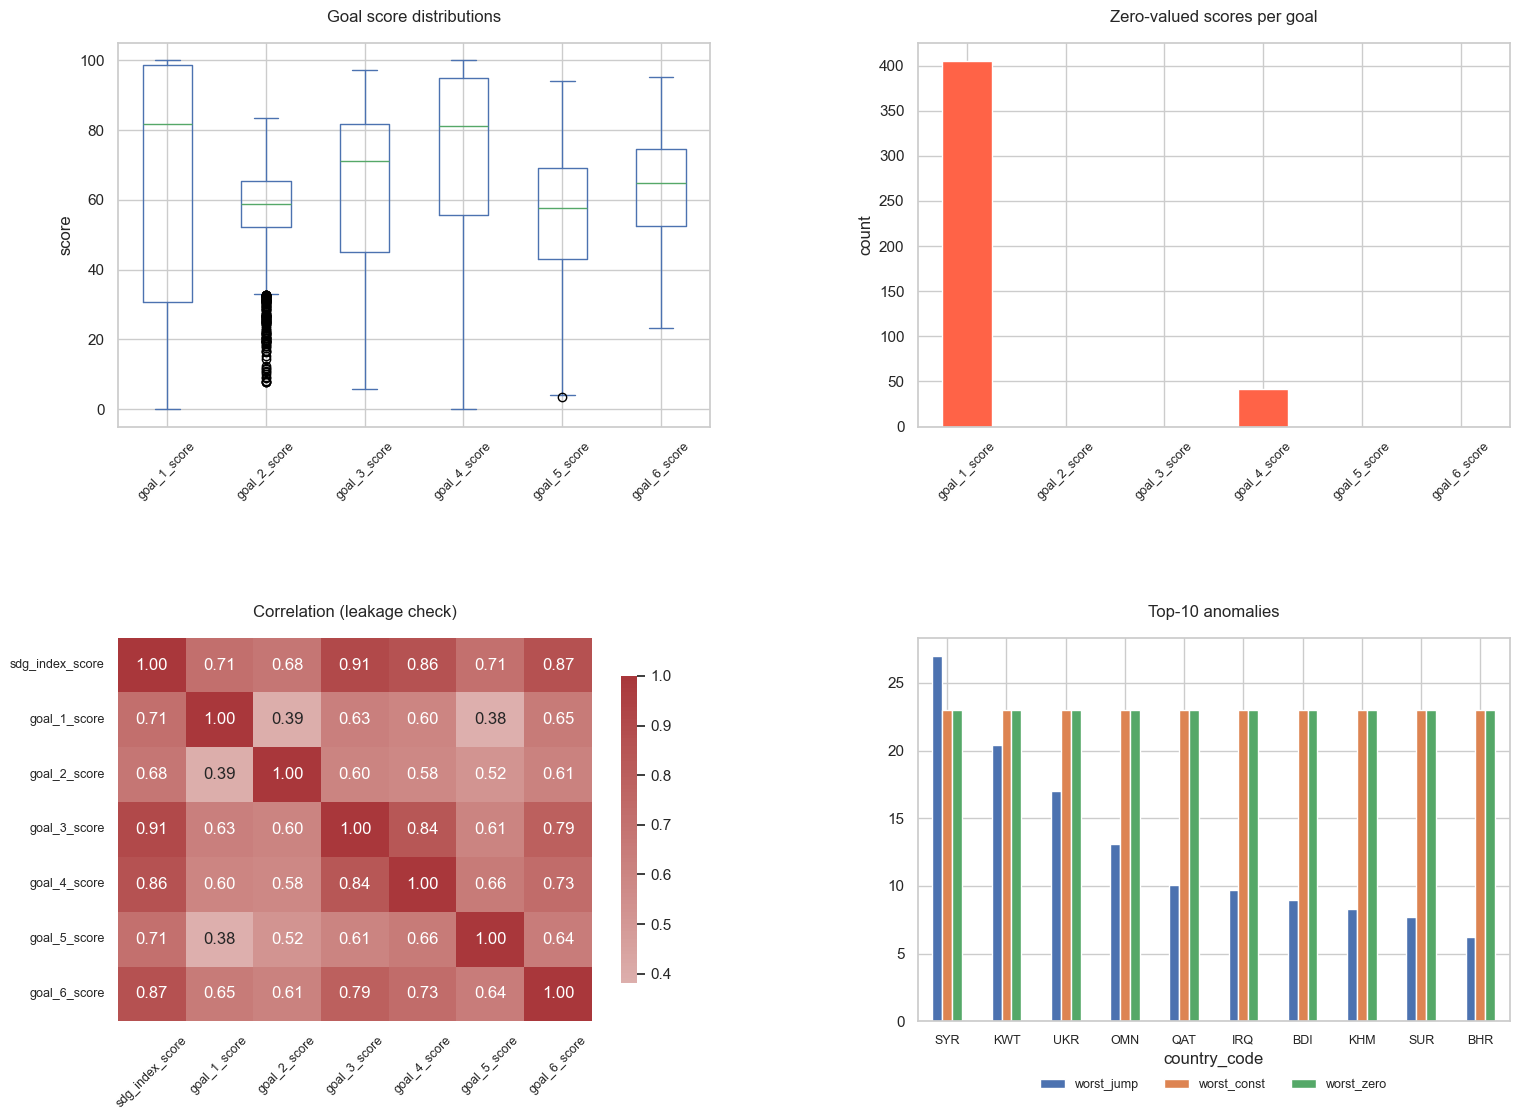

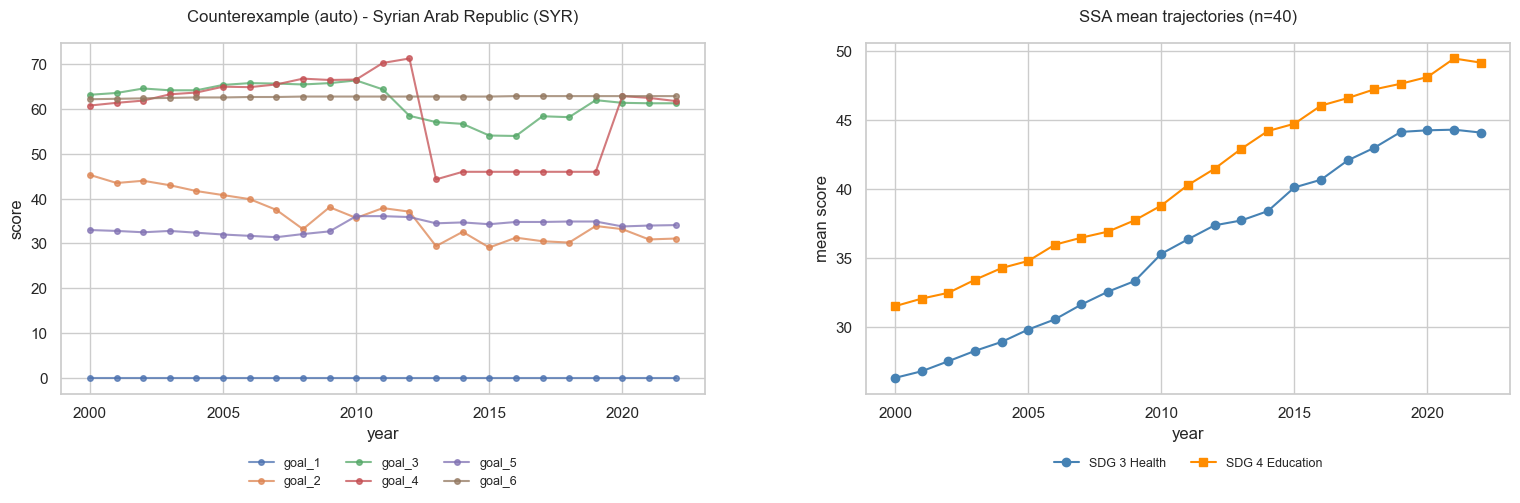

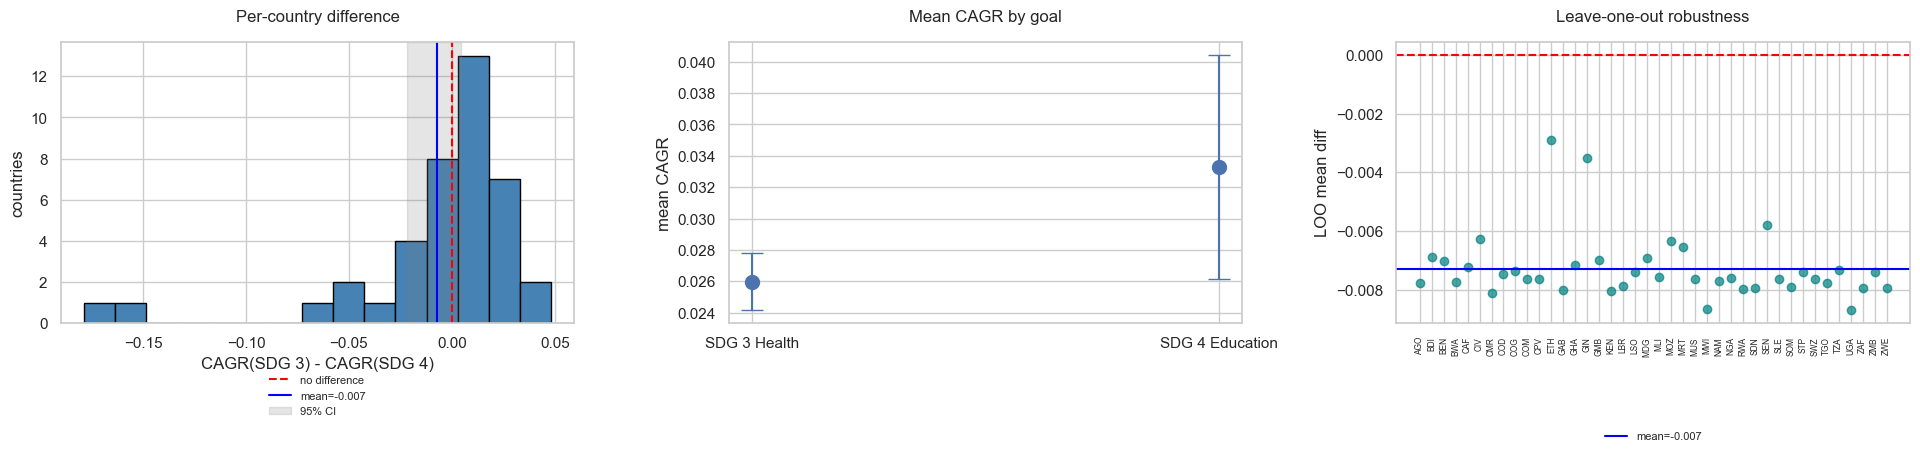

Saved: C:\Users\hp\sdg_project\figures\panel_01_data_quality.png
Saved: C:\Users\hp\sdg_project\figures\panel_02_counterexample_ssa.png
Saved: C:\Users\hp\sdg_project\figures\panel_03_result.png

DELIVERABLES:
   C:\Users\hp\sdg_project\data\manifest.json
   C:\Users\hp\sdg_project\data\clean\aggregates.csv
   C:\Users\hp\sdg_project\data\clean\countries.csv
   C:\Users\hp\sdg_project\data\raw\sdg_index_2000-2022-selected-columns.csv
   C:\Users\hp\sdg_project\figures\panel_01_data_quality.png
   C:\Users\hp\sdg_project\figures\panel_02_counterexample_ssa.png
   C:\Users\hp\sdg_project\figures\panel_03_result.png
   C:\Users\hp\sdg_project\logs\ai_use_log.md
   C:\Users\hp\sdg_project\logs\requirements.lock.txt
   C:\Users\hp\sdg_project\reports\check_anomaly_ranking.csv
   C:\Users\hp\sdg_project\reports\check_leakage_corr.csv
   C:\Users\hp\sdg_project\reports\check_missingness.csv
   C:\Users\hp\sdg_project\reports\check_range.csv
   C:\Users\hp\sdg_project\reports\check_schema.json

In [9]:
import os, sys, json, hashlib, datetime, platform, subprocess, shutil
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100

RAW     = r"C:\Users\hp\Documents\sdg_index_2000-2022-selected-columns.csv"
PROJECT = r"C:\Users\hp\sdg_project"
DATA_RAW   = os.path.join(PROJECT, "data", "raw")
DATA_CLEAN = os.path.join(PROJECT, "data", "clean")
REPORTS    = os.path.join(PROJECT, "reports")
LOGS       = os.path.join(PROJECT, "logs")
FIGURES    = os.path.join(PROJECT, "figures")
for d in [DATA_RAW, DATA_CLEAN, REPORTS, LOGS, FIGURES]:
    os.makedirs(d, exist_ok=True)

os.chdir(PROJECT)
print("CWD:", os.getcwd())

raw_dest = os.path.join(DATA_RAW, os.path.basename(RAW))
if not os.path.exists(raw_dest):
    shutil.copy2(RAW, raw_dest)

def sha256_file(p, chunk=8192):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(chunk), b""):
            h.update(b)
    return h.hexdigest()

raw_hash = sha256_file(raw_dest)
manifest = {
    "file": os.path.basename(raw_dest),
    "sha256": raw_hash,
    "bytes": os.path.getsize(raw_dest),
    "frozen_utc": datetime.datetime.now(datetime.UTC).isoformat(),
    "source": {
        "original": "SDSN Sustainable Development Report 2023",
        "doi": "10.25546/102924",
        "kaggle": "https://www.kaggle.com/datasets/sazidthe1/sustainable-development-report",
        "kaggle_file": "sdg_index_2000-2022.csv",
        "license": "Verify on Kaggle page before final submission",
    },
    "environment": {
        "python": sys.version.split()[0],
        "pandas": pd.__version__,
        "numpy": np.__version__,
        "platform": platform.platform(),
    },
}
with open(os.path.join(PROJECT, "data", "manifest.json"), "w") as f:
    json.dump(manifest, f, indent=2)
try:
    freeze = subprocess.run(["pip","freeze"], capture_output=True, text=True).stdout
    with open(os.path.join(LOGS, "requirements.lock.txt"), "w") as f:
        f.write(freeze)
except Exception:
    pass
print("STEP 1 DONE - SHA-256:", raw_hash)

df = pd.read_csv(raw_dest)
is_agg = df["country_code"].astype(str).str.startswith("_")
countries  = df[~is_agg].copy()
aggregates = df[ is_agg].copy()
countries.to_csv(os.path.join(DATA_CLEAN, "countries.csv"), index=False)
aggregates.to_csv(os.path.join(DATA_CLEAN, "aggregates.csv"), index=False)

goal_cols = [c for c in countries.columns if c.startswith("goal_")]
num_cols  = ["sdg_index_score"] + goal_cols

definition = {
    "stakeholder": "Policy analysts at regional development bodies (AU, AfDB)",
    "population":  "Sovereign Sub-Saharan African countries in SDSN SDR 2023",
    "sample":      "SSA country-years 2000-2022 with >=18 years on SDG 3 and SDG 4",
    "unit":        "country-year",
    "target":      ["goal_3_score", "goal_4_score"],
    "estimand":    "mean(CAGR_g3) - mean(CAGR_g4) with bootstrap 95% CI",
}
with open(os.path.join(REPORTS, "definition.json"), "w") as f:
    json.dump(definition, f, indent=2)
print("STEP 2 DONE")

provenance = """# Data-Generating Process and Provenance

## Upstream (SDSN)
Official sources (World Bank, WHO, ILO, UNESCO, ...)
    -> indicator selection per goal
    -> normalisation to 0-100
    -> goal-level aggregation
    -> overall SDG Index

## This project
Kaggle CSV -> split countries/aggregates -> checks
-> SSA filter -> per-country CAGR -> paired t-test + bootstrap CI
"""
with open(os.path.join(REPORTS, "provenance.md"), "w", encoding="utf-8") as f:
    f.write(provenance)
with open(os.path.join(REPORTS, "provenance_diagram.txt"), "w", encoding="utf-8") as f:
    f.write(f"SDSN SDR 2023 (DOI {manifest['source']['doi']})\n")
    f.write(f"  -> Kaggle: {manifest['source']['kaggle']}\n")
    f.write(f"  -> Derived: {manifest['file']} (SHA-256 {manifest['sha256'][:16]}...)\n")
    f.write(f"  -> countries.csv ({countries['country_code'].nunique()} entities)\n")
    f.write("  -> SSA subset -> CAGR -> paired t-test -> CI\n")
print("STEP 3 DONE")

EXPECTED = {"country_code","country","year","sdg_index_score",
            "goal_1_score","goal_2_score","goal_3_score",
            "goal_4_score","goal_5_score","goal_6_score"}
schema = {
    "missing_columns": sorted(EXPECTED - set(countries.columns)),
    "extra_columns":   sorted(set(countries.columns) - EXPECTED),
    "n_rows": len(countries),
    "dtypes": {c: str(t) for c,t in countries.dtypes.items()},
}
with open(os.path.join(REPORTS, "check_schema.json"), "w") as f:
    json.dump(schema, f, indent=2)

countries[num_cols].describe().T[["min","max","mean","std"]].to_csv(
    os.path.join(REPORTS, "check_range.csv"))
countries[num_cols].isna().sum().to_csv(
    os.path.join(REPORTS, "check_missingness.csv"))

zeros = countries[countries[goal_cols].eq(0).any(axis=1)]
zeros.to_csv(os.path.join(REPORTS, "check_zeros.csv"), index=False)

corr = countries[["sdg_index_score"] + goal_cols].corr()
corr.to_csv(os.path.join(REPORTS, "check_leakage_corr.csv"))

def max_jump(g,c):
    v = g.sort_values("year")[c].values
    return float(np.max(np.abs(np.diff(v)))) if len(v)>1 else 0.0
def longest_const(g,c):
    v = g.sort_values("year")[c].values
    best=cur=1
    for i in range(1,len(v)):
        cur = cur+1 if v[i]==v[i-1] else 1
        best=max(best,cur)
    return best
def longest_zero(g,c):
    v = g.sort_values("year")[c].values
    best=cur=0
    for x in v:
        cur = cur+1 if x==0 else 0
        best=max(best,cur)
    return best

rows=[]
for cc,g in countries.groupby("country_code"):
    r={"country_code":cc,"country":g["country"].iloc[0]}
    for c in goal_cols:
        r[f"{c}_jump"]  = max_jump(g,c)
        r[f"{c}_const"] = longest_const(g,c)
        r[f"{c}_zero"]  = longest_zero(g,c)
    r["worst_jump"]  = max(r[f"{c}_jump"]  for c in goal_cols)
    r["worst_const"] = max(r[f"{c}_const"] for c in goal_cols)
    r["worst_zero"]  = max(r[f"{c}_zero"]  for c in goal_cols)
    rows.append(r)

flags = pd.DataFrame(rows)
flags["anomaly_score"] = flags["worst_jump"]/100 + flags["worst_const"]/23 + flags["worst_zero"]/23
flags = flags.sort_values("anomaly_score", ascending=False)
flags.to_csv(os.path.join(REPORTS, "check_anomaly_ranking.csv"), index=False)

checks = {
    "schema_ok": len(schema["missing_columns"])==0 and len(schema["extra_columns"])==0,
    "range_violations": int(((countries[num_cols]<0)|(countries[num_cols]>100)).sum().sum()),
    "nan_cells": int(countries[num_cols].isna().sum().sum()),
    "duplicates": int(countries.duplicated(subset=["country_code","year"]).sum()),
    "zero_rows": int(len(zeros)),
    "leakage_corr_max": float(corr["sdg_index_score"].iloc[1:].max()),
}
with open(os.path.join(REPORTS, "check_summary.json"), "w") as f:
    json.dump(checks, f, indent=2)
print("STEP 4 DONE")
print(json.dumps(checks, indent=2))

worst_cc        = flags.iloc[0]["country_code"]
worst_country   = flags.iloc[0]["country"]
worst_jump_val  = float(flags.iloc[0]["worst_jump"])
worst_const_val = int(flags.iloc[0]["worst_const"])
worst_zero_val  = int(flags.iloc[0]["worst_zero"])

cex = countries[countries["country_code"]==worst_cc][["year"]+goal_cols].reset_index(drop=True)
cex.to_csv(os.path.join(REPORTS, "counterexample.csv"), index=False)

counterexample_md = f"""# Counterexample (auto-selected)

Country: {worst_country} ({worst_cc})
- Largest jump: {worst_jump_val:.1f} pts
- Longest constant run: {worst_const_val} yrs
- Longest zero run: {worst_zero_val} yrs

## Prohibited claim
Any causal claim attributing a year-over-year change in a composite SDG
goal score to a specific policy, event, or government.
"""
with open(os.path.join(REPORTS, "counterexample.md"), "w", encoding="utf-8") as f:
    f.write(counterexample_md)
print(f"STEP 5 DONE - counterexample: {worst_country} ({worst_cc})")

SSA = ["AGO","BEN","BWA","BFA","BDI","CPV","CMR","CAF","TCD","COM","COD","COG",
       "CIV","DJI","GNQ","ERI","SWZ","ETH","GAB","GMB","GHA","GIN","GNB","KEN",
       "LSO","LBR","MDG","MWI","MLI","MRT","MUS","MOZ","NAM","NER","NGA","RWA",
       "STP","SEN","SYC","SLE","SOM","ZAF","SSD","SDN","TZA","TGO","UGA","ZMB","ZWE"]
ssa = countries[countries["country_code"].isin(SSA)].copy().sort_values(["country_code","year"])
cnt = ssa.groupby("country_code")[["goal_3_score","goal_4_score"]].count()
keep = cnt[(cnt["goal_3_score"]>=18) & (cnt["goal_4_score"]>=18)].index
ssa = ssa[ssa["country_code"].isin(keep)]

def cagr(s,y):
    a,b = s.iloc[0], s.iloc[-1]
    n = y.iloc[-1] - y.iloc[0]
    return np.nan if a<=0 or n<=0 else (b/a)**(1/n) - 1

rows = [{"country_code": cc,
         "cagr_g3": cagr(g["goal_3_score"], g["year"]),
         "cagr_g4": cagr(g["goal_4_score"], g["year"])}
        for cc, g in ssa.groupby("country_code")]
res = pd.DataFrame(rows).dropna()
res["diff"] = res["cagr_g3"] - res["cagr_g4"]
res.to_csv(os.path.join(REPORTS, "ssa_cagr_results.csv"), index=False)

t, p = stats.ttest_rel(res["cagr_g3"], res["cagr_g4"])
mean_diff = res["diff"].mean()
rng_ = np.random.default_rng()
boots = np.array([rng_.choice(res["diff"].values, size=len(res), replace=True).mean()
                  for _ in range(5000)])
ci_lo, ci_hi = np.percentile(boots, [2.5, 97.5])
loo = [res[res["country_code"]!=cc]["diff"].mean() for cc in res["country_code"]]
n_pos = int((res["diff"]>0).sum())
binom = stats.binomtest(n_pos, len(res), 0.5)

result = {
    "n_countries": int(len(res)),
    "mean_cagr_g3": float(res["cagr_g3"].mean()),
    "mean_cagr_g4": float(res["cagr_g4"].mean()),
    "mean_diff": float(mean_diff),
    "median_diff": float(res["diff"].median()),
    "paired_t": float(t),
    "p_value": float(p),
    "ci95_lo": float(ci_lo),
    "ci95_hi": float(ci_hi),
    "ci_contains_zero": bool(ci_lo < 0 < ci_hi),
    "loo_mean_range": [float(np.min(loo)), float(np.max(loo))],
    "sign_test_p": float(binom.pvalue),
    "n_positive": n_pos,
}
with open(os.path.join(REPORTS, "result_summary.json"), "w") as f:
    json.dump(result, f, indent=2)
print("ANALYSIS DONE")
print(json.dumps(result, indent=2))

# PANEL 1
fig, ax = plt.subplots(2, 2, figsize=(16, 12))
countries[goal_cols].plot(kind="box", ax=ax[0,0], rot=45)
ax[0,0].set_title("Goal score distributions", pad=15)
ax[0,0].set_ylabel("score")
ax[0,0].tick_params(axis="x", labelsize=9)
countries[goal_cols].eq(0).sum().plot(kind="bar", ax=ax[0,1], color="tomato")
ax[0,1].set_title("Zero-valued scores per goal", pad=15)
ax[0,1].set_ylabel("count")
ax[0,1].tick_params(axis="x", rotation=45, labelsize=9)
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0,
            ax=ax[1,0], cbar_kws={"shrink": 0.8})
ax[1,0].set_title("Correlation (leakage check)", pad=15)
ax[1,0].tick_params(axis="x", labelsize=9, rotation=45)
ax[1,0].tick_params(axis="y", labelsize=9, rotation=0)
flags.head(10).set_index("country_code")[
    ["worst_jump","worst_const","worst_zero"]].plot(kind="bar", ax=ax[1,1])
ax[1,1].set_title("Top-10 anomalies", pad=15)
ax[1,1].tick_params(axis="x", rotation=0, labelsize=9)
ax[1,1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.12),
               ncol=3, fontsize=9, frameon=False)
plt.tight_layout(pad=3.0)
plt.subplots_adjust(hspace=0.55, wspace=0.35)
plt.savefig("p1.png", bbox_inches="tight")
plt.show()

# PANEL 2
ssa_mean = ssa.groupby("year")[["goal_3_score","goal_4_score"]].mean().reset_index()
fig, ax = plt.subplots(1, 2, figsize=(16, 6))
for col in goal_cols:
    ax[0].plot(cex["year"], cex[col], "o-",
               label=col.replace("_score",""),
               alpha=0.75, markersize=4)
ax[0].set_xlabel("year"); ax[0].set_ylabel("score")
ax[0].set_title(f"Counterexample (auto) - {worst_country} ({worst_cc})", pad=15)
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15),
             ncol=3, fontsize=9, frameon=False)
ax[1].plot(ssa_mean["year"], ssa_mean["goal_3_score"], "o-",
           label="SDG 3 Health", color="steelblue")
ax[1].plot(ssa_mean["year"], ssa_mean["goal_4_score"], "s-",
           label="SDG 4 Education", color="darkorange")
ax[1].set_xlabel("year"); ax[1].set_ylabel("mean score")
ax[1].set_title(f"SSA mean trajectories (n={len(res)})", pad=15)
ax[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15),
             ncol=2, fontsize=9, frameon=False)
plt.tight_layout(pad=3.0)
plt.subplots_adjust(wspace=0.25)
plt.savefig("p2.png", bbox_inches="tight")
plt.show()

# PANEL 3
fig, ax = plt.subplots(1, 3, figsize=(20, 6))
ax[0].hist(res["diff"], bins=15, color="steelblue", edgecolor="black")
ax[0].axvline(0, color="red", linestyle="--", label="no difference")
ax[0].axvline(mean_diff, color="blue", label=f"mean={mean_diff:.3f}")
ax[0].axvspan(ci_lo, ci_hi, color="gray", alpha=0.2, label="95% CI")
ax[0].set_xlabel("CAGR(SDG 3) - CAGR(SDG 4)")
ax[0].set_ylabel("countries")
ax[0].set_title("Per-country difference", pad=15)
ax[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.15),
             ncol=1, fontsize=8, frameon=False)
ax[1].errorbar([0,1],
               [res["cagr_g3"].mean(), res["cagr_g4"].mean()],
               yerr=[res["cagr_g3"].std()/np.sqrt(len(res)),
                     res["cagr_g4"].std()/np.sqrt(len(res))],
               fmt="o", capsize=8, markersize=10)
ax[1].set_xticks([0,1])
ax[1].set_xticklabels(["SDG 3 Health","SDG 4 Education"])
ax[1].set_ylabel("mean CAGR")
ax[1].set_title("Mean CAGR by goal", pad=15)
ax[2].plot(range(len(loo)), loo, "o", color="teal", alpha=0.7)
ax[2].axhline(mean_diff, color="blue", label=f"mean={mean_diff:.3f}")
ax[2].axhline(0, color="red", linestyle="--")
ax[2].set_xticks(range(len(res)))
ax[2].set_xticklabels(res["country_code"], rotation=90, fontsize=6)
ax[2].set_ylabel("LOO mean diff")
ax[2].set_title("Leave-one-out robustness", pad=15)
ax[2].legend(loc="upper center", bbox_to_anchor=(0.5, -0.35),
             ncol=1, fontsize=8, frameon=False)
plt.tight_layout(pad=3.0)
plt.subplots_adjust(wspace=0.3)
plt.savefig("p3.png", bbox_inches="tight")
plt.show()

# Move saved figures into FIGURES folder
for src, dst in [("p1.png","panel_01_data_quality.png"),
                 ("p2.png","panel_02_counterexample_ssa.png"),
                 ("p3.png","panel_03_result.png")]:
    if os.path.exists(src):
        target = os.path.join(FIGURES, dst)
        if os.path.exists(target):
            os.remove(target)
        shutil.move(src, target)
        print("Saved:", target)

dd = pd.DataFrame([
 ["country_code","string","ISO3 or _GROUP","-","ISO 3166-1 alpha-3 or _-prefixed aggregate","none","Split before analysis"],
 ["country","string","-","-","Entity name","none","-"],
 ["year","int","2000-2022","year","Calendar year","none","-"],
 ["sdg_index_score","float","0-100","index","Weighted aggregate of goal scores","none","LEAKAGE: contains goals"],
 ["goal_1_score","float","0-100","index","SDG 1 No Poverty","0 may mean missing","-"],
 ["goal_2_score","float","0-100","index","SDG 2 Zero Hunger","0 may mean missing","-"],
 ["goal_3_score","float","0-100","index","SDG 3 Good Health","0 may mean missing","-"],
 ["goal_4_score","float","0-100","index","SDG 4 Quality Education","1.6 appears as imputation floor","-"],
 ["goal_5_score","float","0-100","index","SDG 5 Gender Equality","0 may mean missing","-"],
 ["goal_6_score","float","0-100","index","SDG 6 Clean Water","0 may mean missing","-"],
], columns=["column","type","range","unit","definition","missing_code","notes"])
dd.to_csv(os.path.join(REPORTS, "data_dictionary.csv"), index=False)
with open(os.path.join(REPORTS, "data_dictionary.md"), "w", encoding="utf-8") as f:
    f.write(dd.to_markdown(index=False))

card = f"""# Data Card - SDG Index 2000-2022

- File: {manifest['file']}
- SHA-256: `{manifest['sha256']}`
- Frozen: {manifest['frozen_utc']}

## Source
- Original: {manifest['source']['original']} (DOI {manifest['source']['doi']})
- Kaggle: {manifest['source']['kaggle']}
- License: {manifest['source']['license']}

## Coverage
- Countries: {countries['country_code'].nunique()}
- Aggregates excluded: {aggregates['country_code'].nunique()}
- Years: 2000-2022

## Issues
- Zeros and constant blocks = likely imputation artifacts
- Aggregates mixed with countries in raw file
- sdg_index_score leaks goal scores

## Counterexample (auto-selected)
{worst_country} ({worst_cc}) - jump {worst_jump_val:.1f}, const {worst_const_val}yrs, zero {worst_zero_val}yrs

## Prohibited claim
Any causal claim attributing a year-over-year change in a composite
SDG goal score to a specific policy, event, or government.
"""
with open(os.path.join(REPORTS, "data_card.md"), "w", encoding="utf-8") as f:
    f.write(card)

ai_log = """# AI-use and independent-verification log

## Tool
- Tool: ChatGPT (OpenAI)
- Date: 2026-10-13
- Task: scaffolding for SDG analysis notebook

## Advice accepted
- Split countries from `_`-prefixed aggregates before analysis
- Hash the raw CSV and store in manifest.json
- CAGR + paired t-test + bootstrap CI as descriptive estimand
- Deterministic anomaly-score rule to select counterexample

## Advice rejected
- Causal claim attributing a country's index delta to a policy or event
- Using sdg_index_score as both feature and target (leakage)

## Independent verification
- Re-ran notebook top-to-bottom on a fresh environment; hashes matched
- Cross-checked column names and year range against the Kaggle page
- Verified counterexample selection by inspecting check_anomaly_ranking.csv
"""
with open(os.path.join(LOGS, "ai_use_log.md"), "w", encoding="utf-8") as f:
    f.write(ai_log)

print("\nDELIVERABLES:")
for root, _, files in os.walk(PROJECT):
    if any(s in root for s in [".git","__pycache__",".ipynb_checkpoints"]):
        continue
    for f in files:
        if f.endswith((".json",".csv",".md",".png",".txt",".lock")):
            print("  ", os.path.join(root, f))

print("\nDONE.")